In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

In [11]:
df= pd.read_csv("Churn_Modelling.csv")


In [12]:
df.head()


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [24]:
df.drop(["RowNumber","CustomerId","Surname"], axis =1, inplace = True)

In [25]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 10000
Number of Columns: 11


In [28]:
df.columns.tolist()

['CreditScore',
 'Geography',
 'Gender',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited']

In [27]:
df.info(



<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  str    
 2   Gender           10000 non-null  str    
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(7), str(2)
memory usage: 859.5 KB


In [29]:
df.describe()



,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [30]:
df.isnull().sum()

CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [31]:
print("Total duplicate records:", df.duplicated().sum())

Total duplicate records: 0


Checking the distribution of the target variable

In [32]:
print(df['Exited'].value_counts())


Exited
0    7963
1    2037
Name: count, dtype: int64


In [33]:
print(df['Exited'].value_counts(normalize=True)*100)

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


##
# EDA -exploratory data analysis

## 1.Age distribution

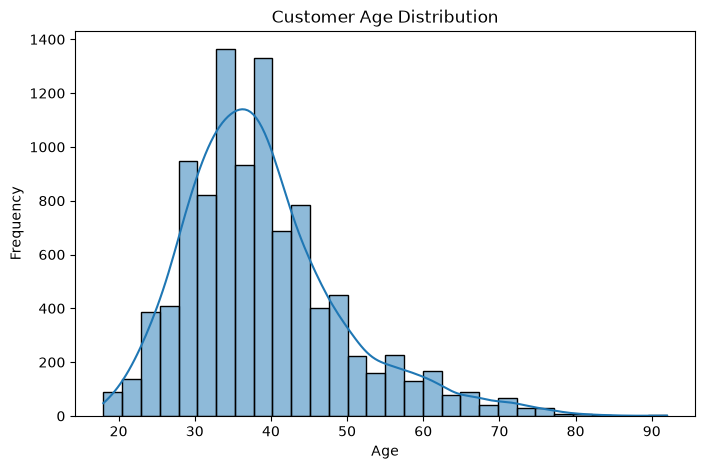

In [35]:
plt.figure(figsize=(8,5))

sns.histplot(df["Age"],bins=30, kde= True)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()






## 2. Balance distribution

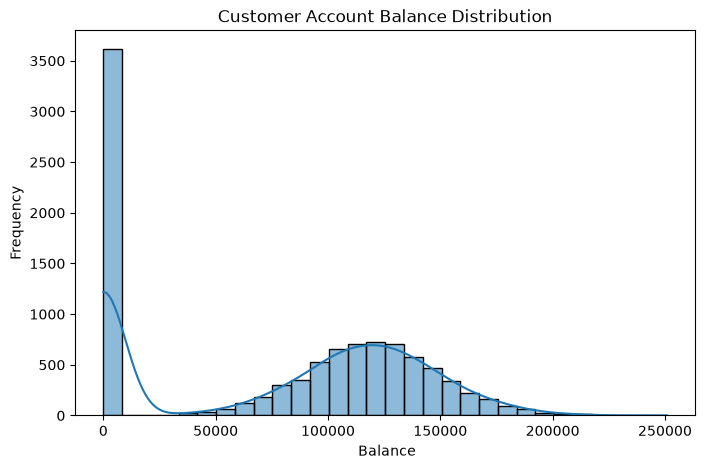

In [37]:
plt.figure(figsize=(8,5))

sns.histplot(df["Balance"], bins=30, kde = True)
plt.title("Customer Account Balance Distribution")
plt.xlabel(" Balance")
plt.ylabel("Frequency")
plt.show()




## 3. Credit Score Distribution

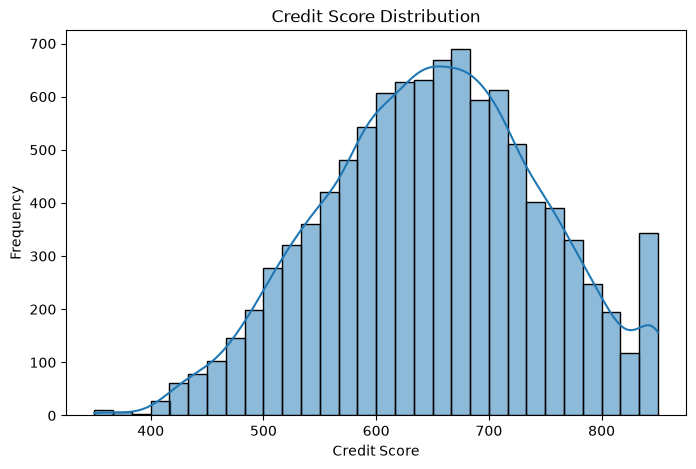

In [39]:
plt.figure(figsize=(8,5))

sns.histplot(df["CreditScore"],bins=30, kde= True)
plt.title("Credit Score Distribution")
plt.xlabel("Credit Score")
plt.ylabel("Frequency")
plt.show()




## 4. Customer Churn Distribution

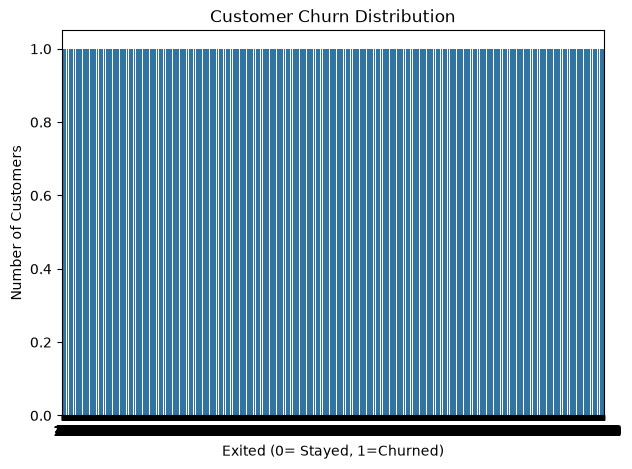

In [44]:
plt.figure(figsize=(7,5))

sns.countplot(df["Exited"])
plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0= Stayed, 1=Churned)")
plt.ylabel("Number of Customers")

plt.show()






## Analysis of categorical feature

## 1.geography distribution

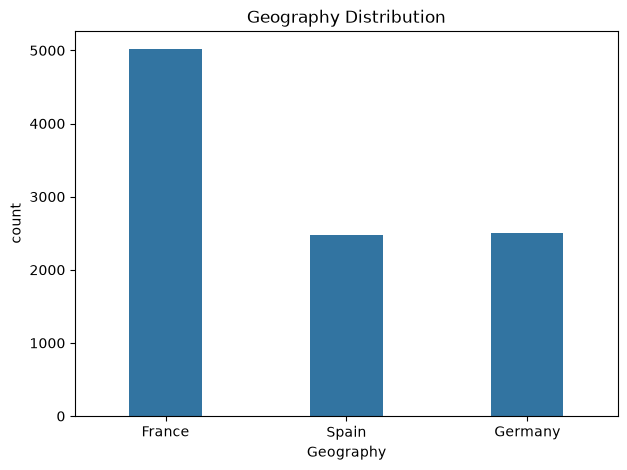

In [47]:
plt.figure(figsize =(7,5))

sns.countplot(data =df, x="Geography",width =0.4)
plt.title("Geography Distribution")
plt.xlabel("Geography")
plt.ylabel("count")
plt.show()

## 2. Gender Distribution

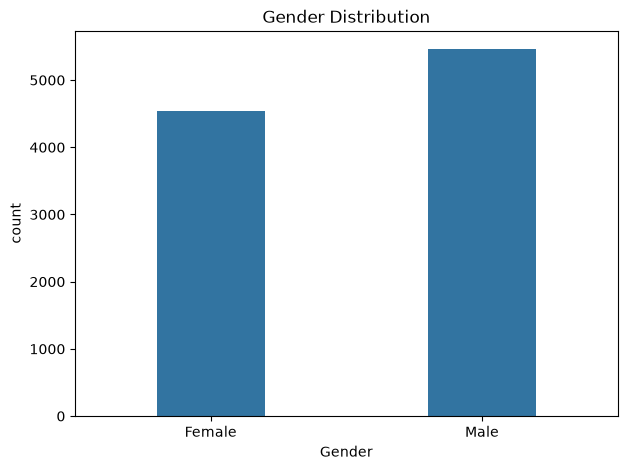

In [49]:
plt.figure(figsize=(7,5))
sns.countplot(data =df, x="Gender",width =0.4)

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("count")
plt.show()



## Phase 2. Bivariate Analysis

## 1.Age vs Customer churn prediction

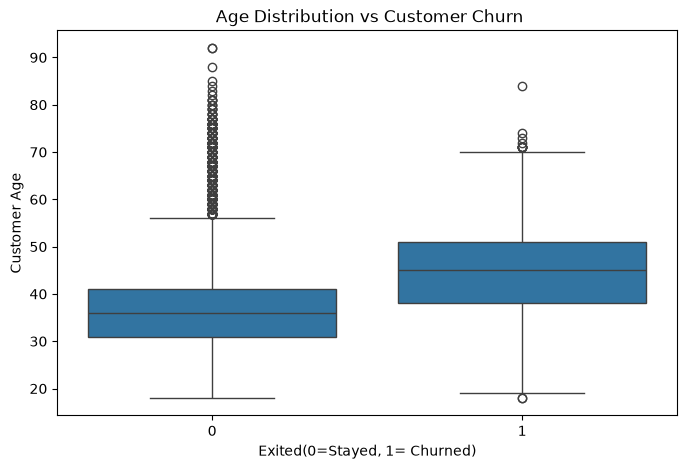

In [51]:
plt.figure(figsize =(8,5))

sns.boxplot(data = df , x= 'Exited', y='Age')
plt.title(" Age Distribution vs Customer Churn")
plt.xlabel("Exited(0=Stayed, 1= Churned)")
plt.ylabel("Customer Age")
plt.show()

## 2. Geography vs Customer Churn

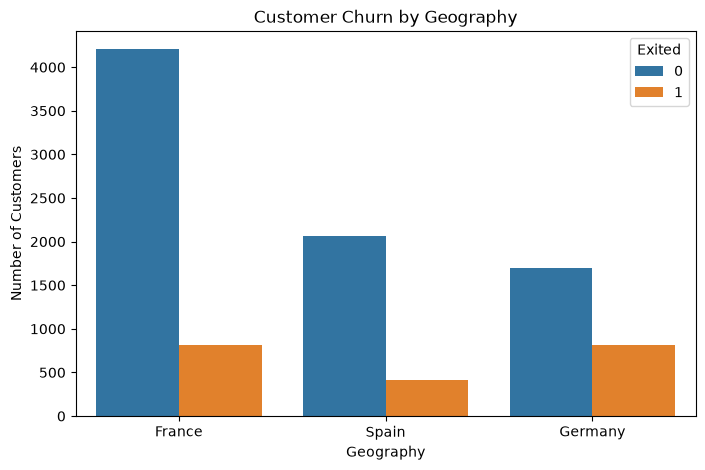

In [52]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Geography', hue='Exited')

plt.title('Customer Churn by Geography')
plt.xlabel('Geography')
plt.ylabel('Number of Customers')

plt.show()

## 3. Gender vs Customer Churn

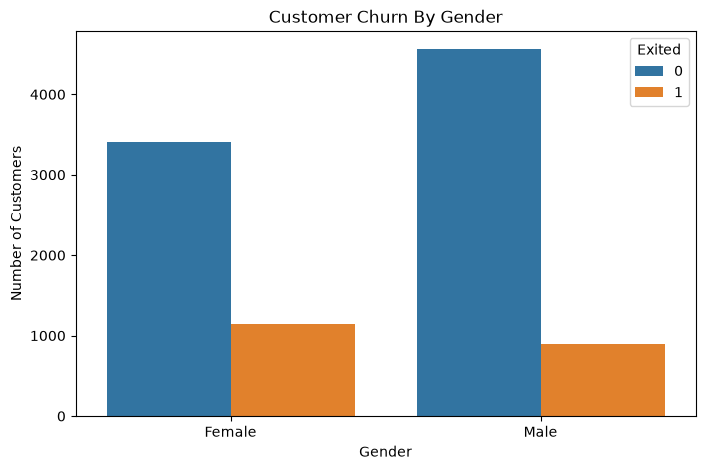

In [53]:
plt.figure(figsize=(8,5))

sns.countplot(data= df, x="Gender", hue='Exited')

plt.title("Customer Churn By Gender")
plt.xlabel("Gender")
plt.ylabel('Number of Customers')
plt.show()

## 4. Account Balance vs Customer Churn

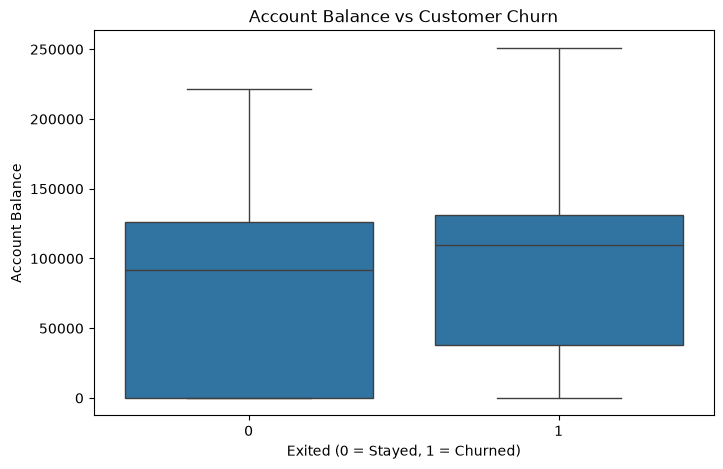

In [54]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Exited', y='Balance')

plt.title('Account Balance vs Customer Churn')
plt.xlabel('Exited (0 = Stayed, 1 = Churned)')
plt.ylabel('Account Balance')
plt.show()

## 5. Tenure vs Customer Churn

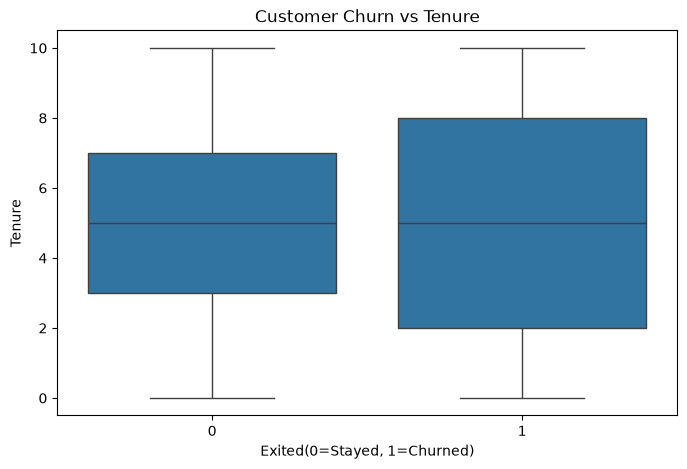

In [55]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x='Exited',y='Tenure')
plt.title("Customer Churn vs Tenure")
plt.xlabel('Exited(0=Stayed, 1=Churned)')
plt.ylabel('Tenure')
plt.show()





## 6. Number of Products vs Customer Churn

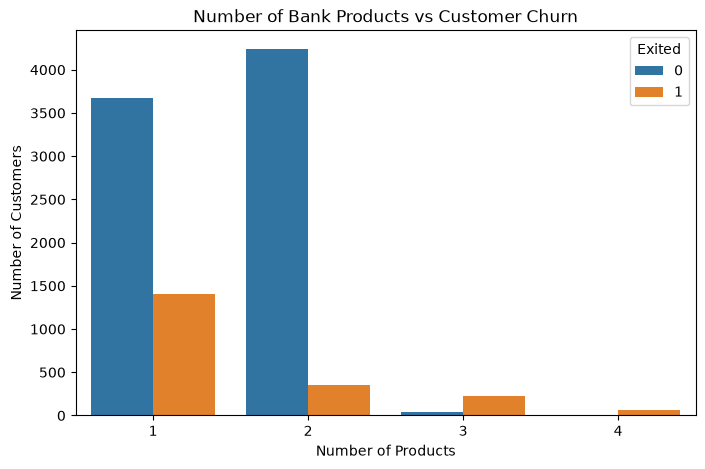

In [56]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='NumOfProducts', hue='Exited')

plt.title('Number of Bank Products vs Customer Churn')
plt.xlabel('Number of Products')
plt.ylabel('Number of Customers')
plt.show()

## 7. Active Membership vs Customer Churn

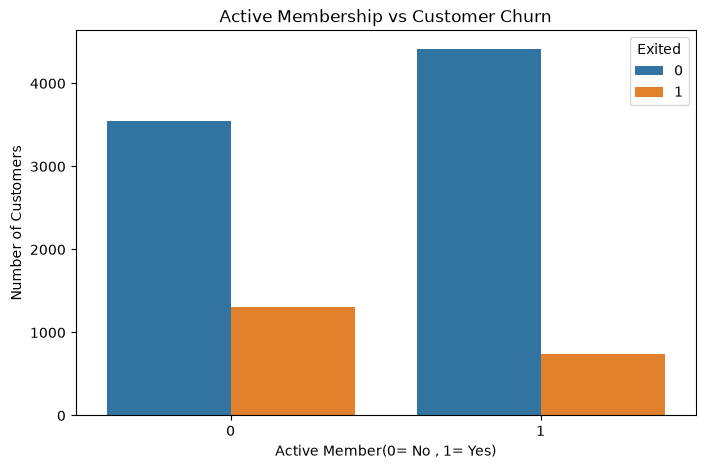

In [57]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='IsActiveMember',hue ='Exited')
plt.title('Active Membership vs Customer Churn')
plt.xlabel('Active Member(0= No , 1= Yes)')
plt.ylabel('Number of Customers')
plt.show()


## 8. Credit Card Ownership vs Customer Churn

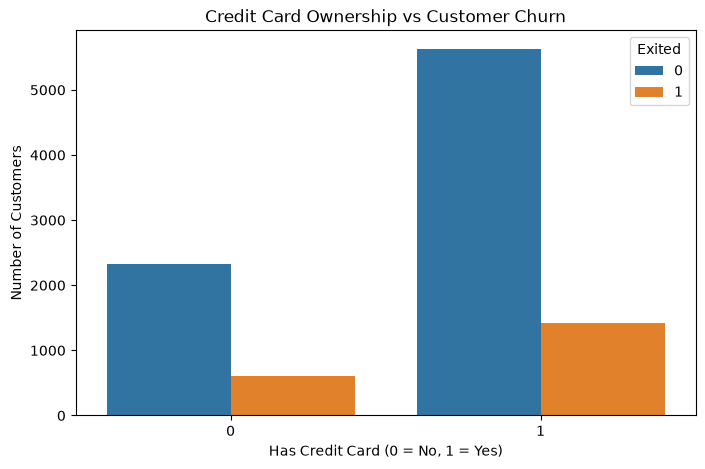

In [58]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='HasCrCard', hue='Exited')

plt.title('Credit Card Ownership vs Customer Churn')
plt.xlabel('Has Credit Card (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')

plt.show()

## 9. Credit Score vs Customer Churn

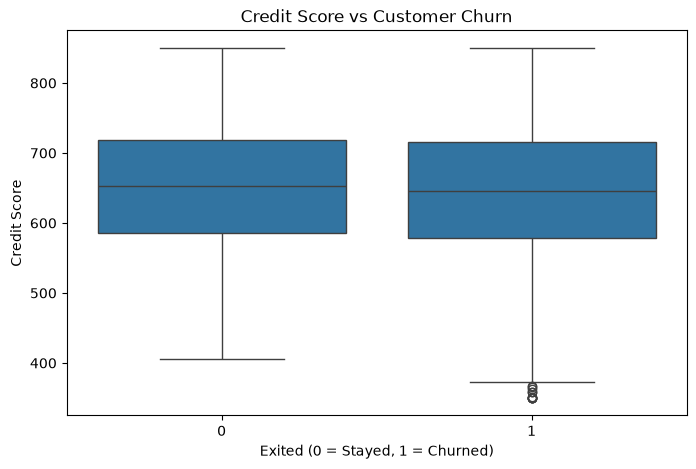

In [59]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Exited', y='CreditScore')

plt.title('Credit Score vs Customer Churn')
plt.xlabel('Exited (0 = Stayed, 1 = Churned)')
plt.ylabel('Credit Score')

plt.show()

## 10. Estimated Salary vs Customer Churn

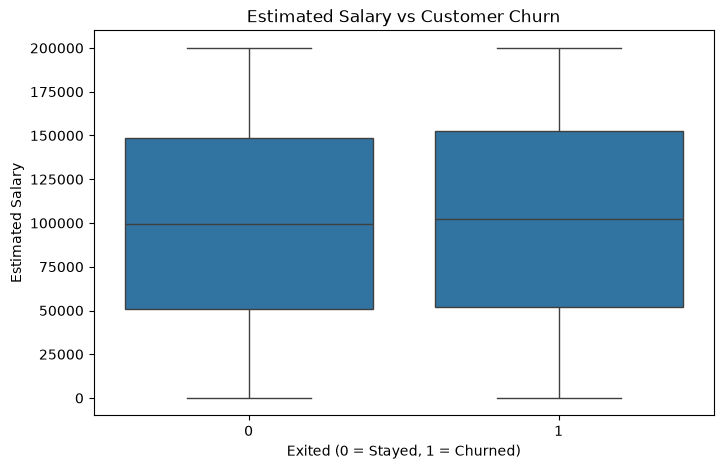

In [60]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Exited', y='EstimatedSalary')

plt.title('Estimated Salary vs Customer Churn')
plt.xlabel('Exited (0 = Stayed, 1 = Churned)')
plt.ylabel('Estimated Salary')

plt.show()

## some plot together

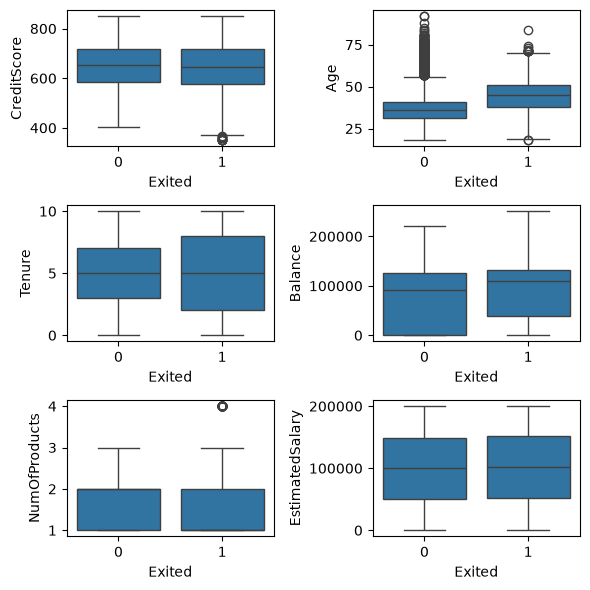

In [64]:
fig, axarr =plt.subplots(3,2, figsize=(6,6))

sns.boxplot(x='Exited', y= 'CreditScore', data=df , ax=axarr[0][0])
sns.boxplot(x='Exited', y= 'Age', data=df , ax=axarr[0][1])

sns.boxplot(x='Exited', y= 'Tenure', data=df , ax=axarr[1][0])
sns.boxplot(x='Exited', y= 'Balance', data=df , ax=axarr[1][1])

sns.boxplot(x='Exited', y= 'NumOfProducts', data=df , ax=axarr[2][0])
sns.boxplot(x='Exited', y= 'EstimatedSalary', data=df , ax=axarr[2][1])

plt.tight_layout()
plt.show()

## Geography-wise churn rate


In [65]:
geo_churn = df.groupby('Geography')['Exited'].mean() *100
print(geo_churn.sort_values(ascending=False))


Geography
Germany    32.443204
Spain      16.673395
France     16.154767
Name: Exited, dtype: float64


 ## gender wise churn rate

In [69]:
gender_churn = df.groupby('Gender')['Exited'].mean() * 100

print(gender_churn.sort_values(ascending=False))

Gender
Female    25.071539
Male      16.455928
Name: Exited, dtype: float64


## Active membership-wise churn rate

In [68]:
active_churn = df.groupby('IsActiveMember')['Exited'].mean() * 100

print(active_churn)

IsActiveMember
0    26.850897
1    14.269074
Name: Exited, dtype: float64


## products-wise churn rate

In [71]:
product_churn = df.groupby('NumOfProducts')['Exited'].mean() *100
print(product_churn.sort_values(ascending = False))

NumOfProducts
4    100.000000
3     82.706767
1     27.714398
2      7.581699
Name: Exited, dtype: float64


## geography wise churn rates

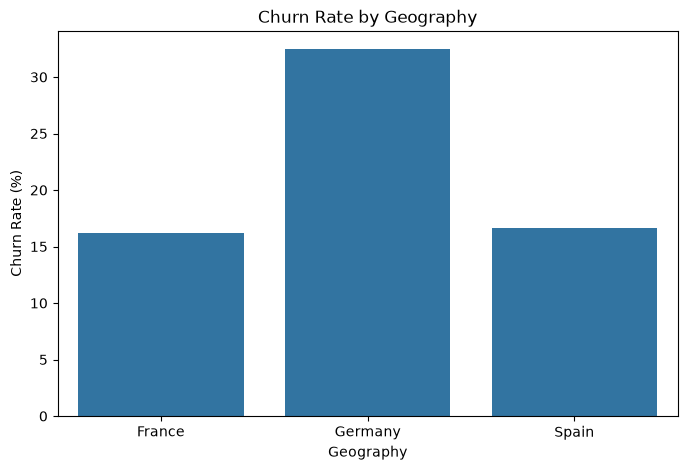

In [72]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=geo_churn.index,
    y=geo_churn.values
)

plt.title('Churn Rate by Geography')
plt.xlabel('Geography')
plt.ylabel('Churn Rate (%)')

plt.show()


## visulaize product wise churn

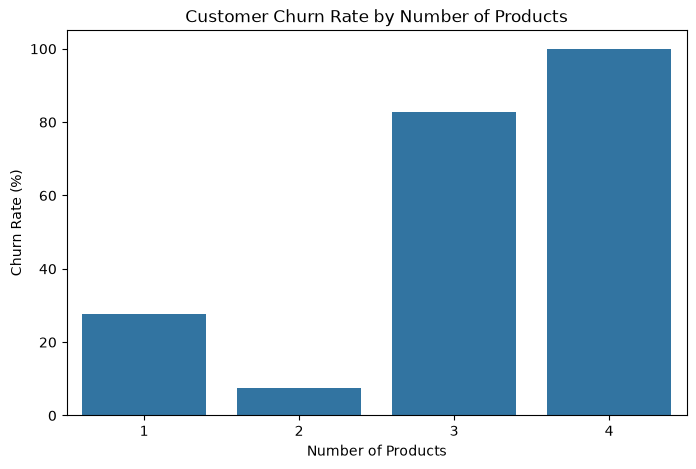

In [73]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=product_churn.index,
    y=product_churn.values
)
plt.title('Customer Churn Rate by Number of Products')
plt.xlabel('Number of Products')
plt.ylabel('Churn Rate (%)')
plt.show()

In [75]:
product_analysis = df.groupby('NumOfProducts')['Exited'].agg(
    Total_Customers='count',
    Churned_Customers='sum',
    Churn_Rate='mean'
)
product_analysis['Churn_Rate'] *= 100
print(product_analysis)

               Total_Customers  Churned_Customers  Churn_Rate
NumOfProducts                                                
1                         5084               1409   27.714398
2                         4590                348    7.581699
3                          266                220   82.706767
4                           60                 60  100.000000


## product distribution

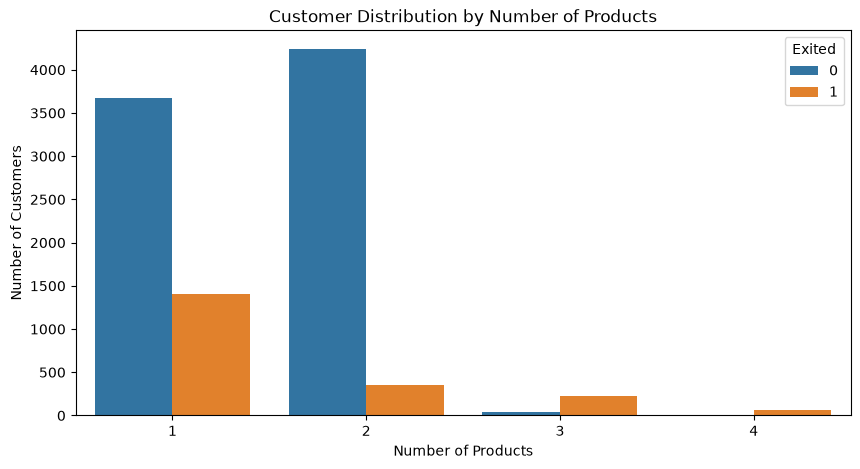

In [76]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='NumOfProducts', hue='Exited')
plt.title('Customer Distribution by Number of Products')
plt.xlabel('Number of Products')
plt.ylabel('Number of Customers')
plt.show()

## correlation analysis

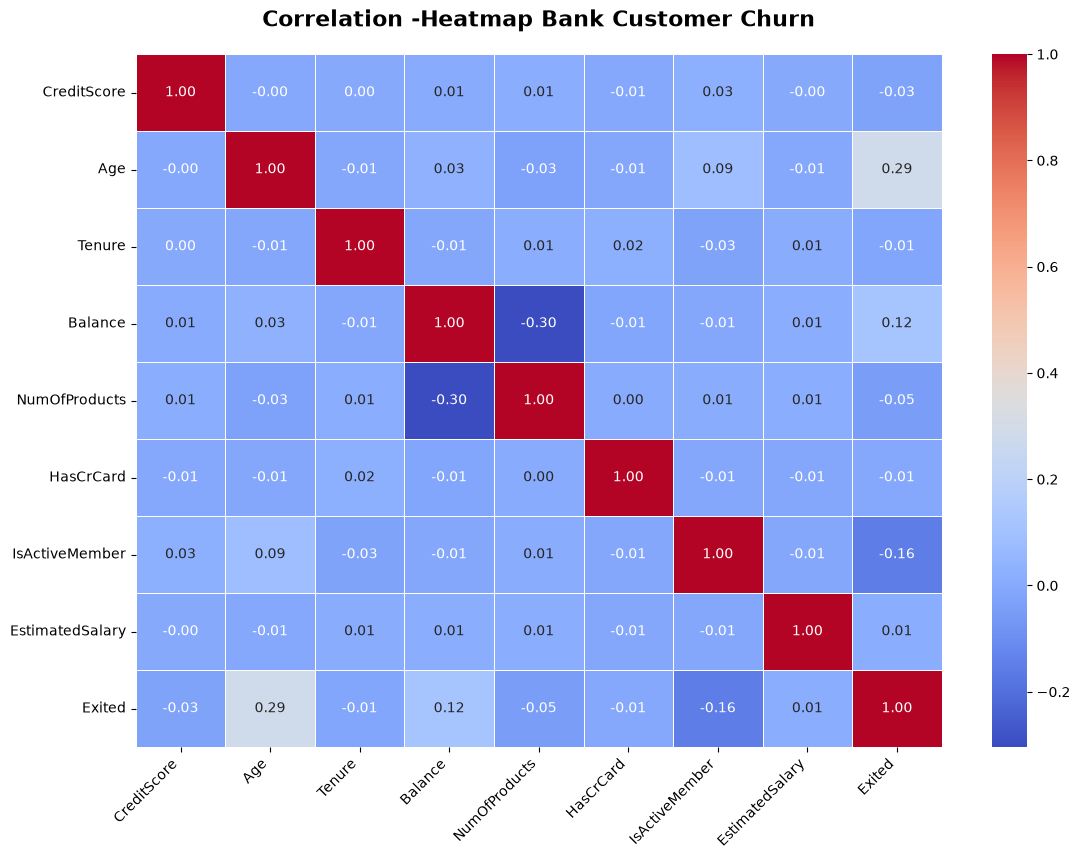

In [89]:
plt.figure(figsize =(13,9))

sns.heatmap(
    df.corr(numeric_only=True),
    annot = True,
    cmap= "coolwarm",
    fmt =".2f",
    linewidth =0.5
)
plt.title("Correlation -Heatmap Bank Customer Churn" , fontsize =16, fontweight ="bold" , pad =20)
plt.xticks(rotation=45, ha="right")
plt.show()




## Feature Engineering

## 1. Balance to salary ratio

In [90]:
df['Balance_to_salary']= df['Balance']/df["EstimatedSalary"]



In [91]:
df['tenure_by_age']=df["Tenure"]/df["Age"]

In [92]:
df.shape

(10000, 13)

## Feature Encoding

## 1. Label Encoding- Gender

In [93]:
from sklearn.preprocessing import LabelEncoder



In [94]:
le= LabelEncoder()

In [95]:
df["Gender"] = le.fit_transform(df["Gender"])

## 2. One -Hot Encoding Geography

In [97]:
df= pd.get_dummies(df,columns =['Geography'], drop_first = True )

In [98]:
df.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Balance_to_salary,tenure_by_age,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,0.000000,0.047619,False,False
1,608,0,41,1,83807.86,1,0,1,112542.58,0,0.744677,0.024390,False,True
2,502,0,42,8,159660.80,3,1,0,113931.57,1,1.401375,0.190476,False,False
3,699,0,39,1,0.00,2,0,0,93826.63,0,0.000000,0.025641,False,False
4,850,0,43,2,125510.82,1,1,1,79084.10,0,1.587055,0.046512,False,True


## Defining Feature and Target Variable

In [99]:
X= df.drop("Exited", axis=1)
y= df["Exited"]

## spliting the dataset

In [100]:
from sklearn.model_selection import (train_test_split)


In [101]:
X_train , X_test , y_train ,y_test =train_test_split(X,y,test_size=0.2,random_state =42)

In [102]:
X_train.shape

(8000, 13)

In [103]:
y_test.shape

(2000,)

## Feature Scaling

In [104]:
from sklearn.preprocessing import StandardScaler

In [106]:
sc= StandardScaler()

In [107]:
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

## Model Training

Logistic Regression

KNN Classifier

Naive Bayes

Random Forest

XGB Classifier

ANN - Artificial Neural Network

In [123]:
from sklearn.metrics import  accuracy_score ,precision_score ,recall_score, f1_score , roc_auc_score

In [109]:
from sklearn.linear_model import (LogisticRegression)
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train,y_train)
y_pred_lr = lr_model.predict(X_test)


In [124]:
lr_accuracy= accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test,y_pred_lr)
lr_recall= recall_score(y_test,y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)
lr_roc_auc = roc_auc_score(y_test, lr_model.predict_proba(X_test)[:, 1])

In [125]:
print("Accuracy:" ,lr_accuracy)
print("Precision:",lr_precision)
print("recall:" ,lr_recall)
print("f1:" , lr_f1)
print("roc_auc:",lr_roc_auc)

Accuracy: 0.8125
Precision: 0.56
recall: 0.21374045801526717
f1: 0.30939226519337015
roc_auc: 0.7795237439256687


In [126]:
from sklearn.metrics import confusion_matrix

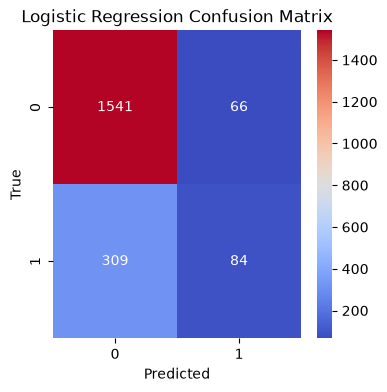

In [127]:
cm = confusion_matrix(y_test,y_pred_lr)

plt.figure(figsize =(4,4))

sns.heatmap(cm,annot =True,cmap ='coolwarm',fmt ='d')
plt.title('Logistic Regression Confusion Matrix' )
plt.xlabel('Predicted' )
plt.ylabel('True')
plt.show()


In [128]:
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_lr))


Classification Report:

              precision    recall  f1-score   support

           0       0.83      0.96      0.89      1607
           1       0.56      0.21      0.31       393

    accuracy                           0.81      2000
   macro avg       0.70      0.59      0.60      2000
weighted avg       0.78      0.81      0.78      2000



In [129]:
cm

array([[1541,   66],
       [ 309,   84]])

In [130]:
model_results =[]

model_results.append({"Model":"Logistic Regression",
                      "Accuracy":lr_accuracy,
                      "Precision":lr_precision,
                      "Recall":lr_recall,
                      "F1 Score":lr_f1,
                      "ROC AUC":lr_roc_auc})


## KNN Classifier

In [131]:
from sklearn.neighbors import KNeighborsClassifier

In [132]:
knn_model =KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

In [133]:
knn_accuracy = accuracy_score(y_test,y_pred_knn)
knn_precision = precision_score(y_test, y_pred_knn )
knn_recall = recall_score(y_test, y_pred_knn )
knn_f1 = f1_score(y_test, y_pred_knn )
knn_roc_auc = roc_auc_score(y_test, knn_model.predict_proba(X_test)[:,1])

In [134]:
print("Accuracy:" ,knn_accuracy)
print("Precision:",knn_precision)
print("recall:" ,knn_recall)
print("f1:" , knn_f1)
print("roc_auc:",knn_roc_auc)

Accuracy: 0.831
Precision: 0.6170212765957447
recall: 0.36895674300254455
f1: 0.46178343949044587
roc_auc: 0.7623438170472376


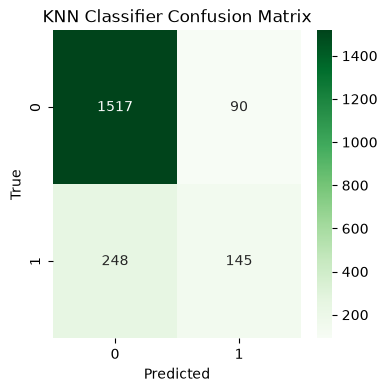

In [137]:
cm = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(4,4))
sns.heatmap(cm, annot = True, cmap = 'Greens', fmt ='d')

plt.title("KNN Classifier Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


In [138]:
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_knn))


Classification Report:

              precision    recall  f1-score   support

           0       0.86      0.94      0.90      1607
           1       0.62      0.37      0.46       393

    accuracy                           0.83      2000
   macro avg       0.74      0.66      0.68      2000
weighted avg       0.81      0.83      0.81      2000



In [139]:
model_results.append({"Model":"KNN Classifier",
                      "Accuracy": knn_accuracy,
                      "Precision":knn_precision,
                      "Recall":knn_recall,
                      "F1 Score":knn_f1,
                      "ROC AUC":knn_roc_auc})


## Naive bayes

In [140]:
from sklearn.naive_bayes import GaussianNB

In [143]:
nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

y_pred_nb =nb_model.predict(X_test)

In [144]:
nb_accuracy = accuracy_score(y_test, y_pred_nb)
nb_precision = precision_score(y_test, y_pred_nb)
nb_recall = recall_score(y_test, y_pred_nb)
nb_f1 = f1_score(y_test, y_pred_nb)

nb_roc_auc = roc_auc_score(
    y_test,
    nb_model.predict_proba(X_test)[:, 1]
)

In [145]:
print("Accuracy:" ,nb_accuracy)
print("Precision:",nb_precision)
print("recall:" ,nb_recall)
print("f1:" , nb_f1)
print("roc_auc:",nb_roc_auc)

Accuracy: 0.8275
Precision: 0.6967213114754098
recall: 0.21628498727735368
f1: 0.3300970873786408
roc_auc: 0.7998150584830046


In [146]:
cm_nb = confusion_matrix(y_test,y_pred_nb)
cm_nb

array([[1570,   37],
       [ 308,   85]])

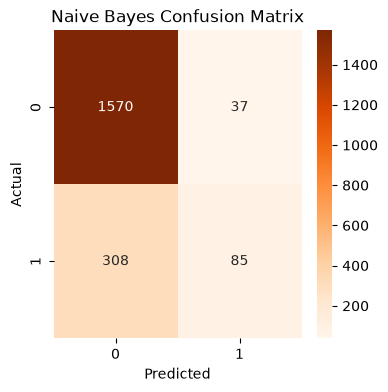

In [147]:
plt.figure(figsize=(4,4))

sns.heatmap(cm_nb, annot=True, cmap='Oranges', fmt='d')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Naive Bayes Confusion Matrix")

plt.show()


In [148]:
model_results.append({
    "Model": "Naive Bayes",
    "Accuracy": nb_accuracy,
    "Precision": nb_precision,
    "Recall": nb_recall,
    "F1 Score": nb_f1,
    "ROC AUC": nb_roc_auc
})

## Random Forest

In [149]:
from sklearn.ensemble import RandomForestClassifier

In [153]:
rf_model = RandomForestClassifier(n_estimators=100, random_state =42)
rf_model.fit(X_train, y_train)
y_pred_rf =rf_model.predict(X_test)

In [158]:
rf_accuracy = accuracy_score(y_test,y_pred_rf)
rf_precision= precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1= f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test,rf_model.predict_proba(X_test)[:,1])

print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("recall:", rf_recall)
print("f1:", rf_f1)
print("roc_auc:", rf_roc_auc)

Accuracy: 0.869
Precision: 0.7651821862348178
recall: 0.48091603053435117
f1: 0.590625
roc_auc: 0.8600002216764759


In [159]:
model_results.append({
    "Model": "Random Forest",
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1 Score": rf_f1,
    "ROC AUC": rf_roc_auc
})

## XG Boost

In [162]:
from xgboost import XGBClassifier


In [163]:
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

In [164]:
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb)
xgb_recall = recall_score(y_test, y_pred_xgb)
xgb_f1 = f1_score(y_test, y_pred_xgb)

xgb_roc_auc = roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:, 1] )

print("Accuracy:", xgb_accuracy)
print("Precision:", xgb_precision)
print("Recall:", xgb_recall)
print("F1 Score:", xgb_f1)
print("ROC-AUC:", xgb_roc_auc)

Accuracy: 0.8655
Precision: 0.7520325203252033
Recall: 0.4707379134860051
F1 Score: 0.5790297339593115
ROC-AUC: 0.8727869958245652


In [165]:
model_results.append({"Model":"XGBoost",
                      "Accuracy":xgb_accuracy,
                      "Precision":xgb_precision,
                      "Recall":xgb_recall,
                      "F1 Score":xgb_f1,
                      "ROC AUC":xgb_roc_auc})

## ANN - Artificial Neural Network

In [166]:
%pip install tensorflow

  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
  Using cached charset_normalizer-3.5.2-cp313-cp313-win_amd64.whl.metadata (47 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
  Using cached wheel-0.48.0-py3-none-any.whl.metadata (2.3 kB)
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 1.8/351.2 MB 10.2 MB/s eta 0:00:35
   ---------------------------------------- 3.9/351.2 MB 9.6 MB/s eta 0:00:37
    --------------------------------------- 5.8/351.2 MB 9.5 MB/s eta 0:00:37
    --------------------------------------- 7.6/351.2 MB 9.4 MB/s eta 0:00:37
   - -------------------------------------- 9.4/351.2 MB 9.3 MB/s 


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [167]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [168]:
ann_model = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(32, activation='relu'),
    Dropout(0.2),

    Dense(1, activation='sigmoid')
])

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,009 (11.75 KB)

 Trainable params: 3,009 (11.75 KB)

 Non-trainable params: 0 (0.00 B)

In [169]:
ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [170]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = ann_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7884 - loss: 0.4924 - val_accuracy: 0.8231 - val_loss: 0.4161
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8156 - loss: 0.4413 - val_accuracy: 0.8406 - val_loss: 0.3950
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8245 - loss: 0.4135 - val_accuracy: 0.8450 - val_loss: 0.3799
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8373 - loss: 0.3967 - val_accuracy: 0.8481 - val_loss: 0.3683
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.8456 - loss: 0.3829 - val_accuracy: 0.8519 - val_loss: 0.3600
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.8489 - loss: 0.3711 - val_accuracy: 0.8487 - val_loss: 0.3565
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8473 - loss: 0.3675 - val_accuracy: 0.8519 - val_loss: 0.3511
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8503 - loss: 0.3624 - val_accuracy

In [171]:
y_prob_ann = ann_model.predict(X_test).ravel()

y_pred_ann = (y_prob_ann >= 0.5).astype(int)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


In [172]:
ann_accuracy = accuracy_score(y_test, y_pred_ann)
ann_precision = precision_score(y_test, y_pred_ann)
ann_recall = recall_score(y_test, y_pred_ann)
ann_f1 = f1_score(y_test, y_pred_ann)
ann_roc_auc = roc_auc_score(y_test, y_prob_ann)

print("Accuracy:", ann_accuracy)
print("Precision:", ann_precision)
print("Recall:", ann_recall)
print("F1 Score:", ann_f1)
print("ROC-AUC:", ann_roc_auc)

Accuracy: 0.863
Precision: 0.7351778656126482
Recall: 0.4732824427480916
F1 Score: 0.5758513931888545
ROC-AUC: 0.8596645401559021


In [173]:
model_results.append({
    "Model": "ANN",
    "Accuracy": ann_accuracy,
    "Precision": ann_precision,
    "Recall": ann_recall,
    "F1 Score": ann_f1,
    "ROC AUC": ann_roc_auc
})

In [174]:
results_df = pd.DataFrame(model_results)

results_df.sort_values(
    by="ROC AUC",
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,XGBoost,0.8655,0.752033,0.470738,0.579030,0.872787
1,Random Forest,0.8690,0.765182,0.480916,0.590625,0.860000
2,ANN,0.8630,0.735178,0.473282,0.575851,0.859665
3,Naive Bayes,0.8275,0.696721,0.216285,0.330097,0.799815
4,Logistic Regression,0.8125,0.560000,0.213740,0.309392,0.779524
5,KNN Classifier,0.8310,0.617021,0.368957,0.461783,0.762344


## Final model comparison

In [175]:
results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(
    by="ROC AUC",
    ascending=False
).reset_index(drop=True)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,XGBoost,0.8655,0.7520,0.4707,0.5790,0.8728
1,Random Forest,0.8690,0.7652,0.4809,0.5906,0.8600
2,ANN,0.8630,0.7352,0.4733,0.5759,0.8597
3,Naive Bayes,0.8275,0.6967,0.2163,0.3301,0.7998
4,Logistic Regression,0.8125,0.5600,0.2137,0.3094,0.7795
5,KNN Classifier,0.8310,0.6170,0.3690,0.4618,0.7623


## Bar chart comparing ROC-AUC

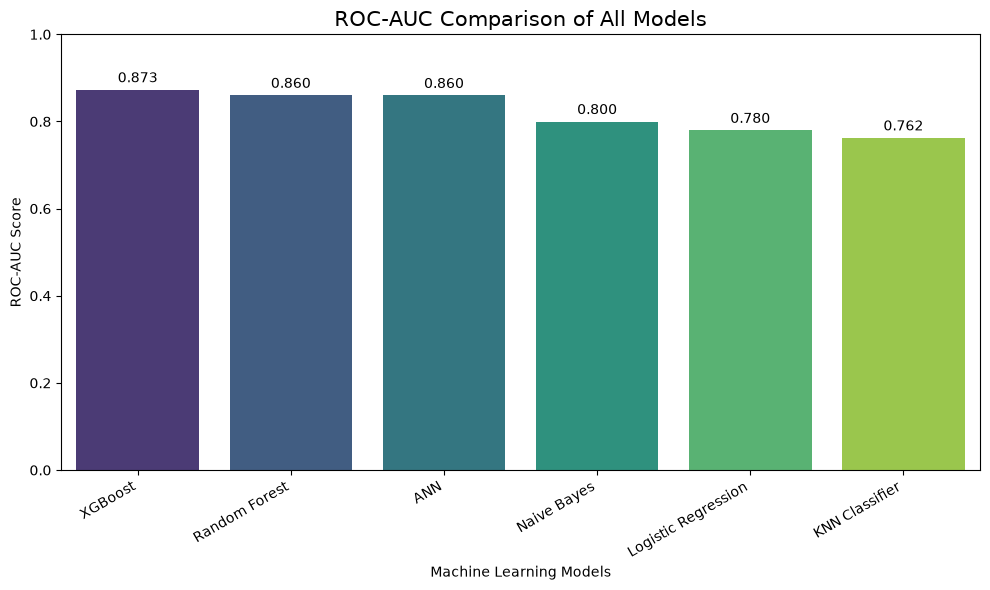

In [179]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(data=results_df,x="Model",y="ROC AUC",hue="Model",palette="viridis",legend=False)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.title("ROC-AUC Comparison of All Models", fontsize=15)
plt.xlabel("Machine Learning Models")
plt.ylabel("ROC-AUC Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

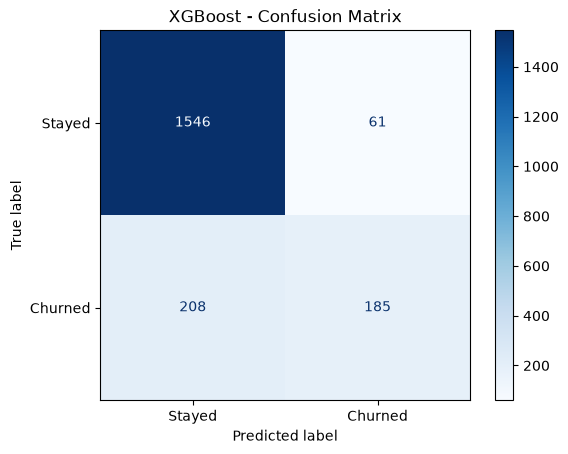

In [180]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# XGBoost confusion matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Stayed", "Churned"]
)

disp.plot(cmap="Blues")
plt.title("XGBoost - Confusion Matrix")
plt.show()

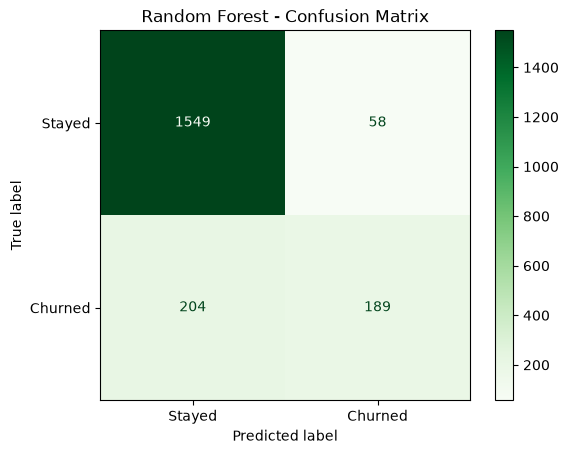

In [181]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Stayed", "Churned"]
)

disp.plot(cmap="Greens")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [183]:
import joblib
joblib.dump(xgb_model, "xgboost_churn_model.pkl")
print("XGBoost model saved successfully!")

XGBoost model saved successfully!


In [184]:
joblib.dump(sc, "standard_scaler.pkl")
print("StandardScaler saved successfully!")

StandardScaler saved successfully!


In [185]:
# Save Gender encoder
joblib.dump(le, "gender_encoder.pkl")

# Save original feature column names and order
feature_names = X.columns.tolist()

joblib.dump(feature_names, "feature_names.pkl")

print("Gender encoder saved!")
print("Feature names saved!")
print(feature_names)

Gender encoder saved!
Feature names saved!
['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Balance_to_salary', 'tenure_by_age', 'Geography_Germany', 'Geography_Spain']


In [186]:
print("Features:", len(feature_names))
print("Model expects:", xgb_model.n_features_in_)

Features: 13
Model expects: 13
